# MHT (Multi Hypothesis Tracking) Test

Here the implemented MHT algorithm is tested.  

**Important:**  
Due to time constraints it was not possible to debug the algorithm and do a longer analysis.

## Setup and Imports

In [1]:
%matplotlib widget

# standard library imports
import sys
import os
import logging
from pathlib import Path
from datetime import datetime
from collections import defaultdict

# third-party imports
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import display
import tqdm

# Add the project root to the path to ensure imports work correctly
project_root = Path().absolute().parents[1]
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

# Import local modules
from utils import rosbag_utils, df_utils, plotting_utils
import multi_target_tracking as mtt
# Reload imports to ensure the latest code is used
import importlib
importlib.reload(sys.modules['utils'])
importlib.reload(sys.modules['multi_target_tracking'])

# Update references after reload
import utils.df_utils as dfu
import utils.plotting_utils as pu
import utils.rosbag_utils as rbu
import utils.sensor_sim as ss
import multi_target_tracking as mtt

In [ ]:
# plotting font sizes
pu.plt.rcParams.update({'font.size': 16,
                        'axes.labelsize': 16,
                        'axes.titlesize': 16,
                        'xtick.labelsize': 16,
                        'ytick.labelsize': 16,
                        'legend.fontsize': 16,
                        'figure.titlesize': 24})

## Configuration

In [3]:
## CONFIGURATION
BAG_PATH = os.path.join(project_root, 'data/gazebo_flight__2025-02-03-16-25-02.bag')
script_name = "05_MHT"
LOG_DIR = os.path.join(project_root, f'logs/{script_name}')
RESULTS_DIR = os.path.join(project_root, f'results/{script_name}')
PLOTS_DIR = os.path.join(RESULTS_DIR, "plots")
# Create directories if they don't exist
os.makedirs(LOG_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(PLOTS_DIR, exist_ok=True)

## LOGGING CONFIGURATION
# Configure logging to output to both console and file
log_file = LOG_DIR + f"/{script_name}_{datetime.now().strftime('%Y%m%d_%H%M%S')}.log"
# Create logger
logger = logging.getLogger()
logger.setLevel(logging.INFO)
# Clear any existing handlers
for handler in logger.handlers[:]: 
    logger.removeHandler(handler)
# Create file handler
file_handler = logging.FileHandler(log_file)
file_handler.setLevel(logging.DEBUG)
file_format = logging.Formatter('%(asctime)s - %(name)s - %(levelname)s - %(message)s')
file_handler.setFormatter(file_format)
# Create console handler
console_handler = logging.StreamHandler()
console_handler.setLevel(logging.INFO)
console_format = logging.Formatter('%(levelname)s: %(message)s')
console_handler.setFormatter(console_format)
# Add handlers to logger
logger.addHandler(file_handler)
logger.addHandler(console_handler)

# Log to file and console
logger.info("Notebook started - MHT tracker demo")

## ROSBAG READER
# Load the bag file
bag_path = Path(BAG_PATH)
if not bag_path.exists():
    raise FileNotFoundError(f"Rosbag file not found: {bag_path}")
bag_reader = rbu.load_rosbag(bag_path)
# rbu.display_rosbag_info(bag_reader)

INFO: Notebook started - MHT tracker demo


## Data Extraction and Processing

Extract projection data and ground truth for comparison.

In [4]:
## DATA EXTRACTION
# Define topics to analyze
topics = [
    "/machine_1/target_tracker/MTT/GT/target0",
    "/machine_1/target_tracker/MTT/GT/target1",
    "/machine_1/object_detections/projected_to_world"
]

# Extract and process data
topic_data = {}
for topic in topics:
    data = rbu.create_df_from_bag(bag_reader, topic)
    topic_data[topic] = data

INFO: Processing topic: '/machine_1/target_tracker/MTT/GT/target0' with message type: 'geometry_msgs/msg/PoseWithCovarianceStamped'
INFO: Processing topic: '/machine_1/target_tracker/MTT/GT/target1' with message type: 'geometry_msgs/msg/PoseWithCovarianceStamped'
INFO: Processing topic: '/machine_1/object_detections/projected_to_world' with message type: 'geometry_msgs/msg/PoseWithCovarianceStamped'


In [ ]:
## PROCESS DATA FOR TRACKING BASED ON PROJECTED OBJECT DETECTIONS
# to get all measurements from a camera frame the measurements need to 
# be grouped by time

## PROJECTED OBJECT DETECTIONS
proj_time, proj_measurements = dfu.dataframe_to_measurements(
    topic_data["/machine_1/object_detections/projected_to_world"]
    )

# Group measurements by timestamp
measurements_by_time = defaultdict(list)
for time, meas in zip(proj_time, proj_measurements):
    # Round timestamp to nearest millisecond to handle small timestamp differences
    # within the same frame
    rounded_time = round(time * 1000) / 1000
    measurements_by_time[rounded_time].append(meas)

# Convert to list of measurement groups sorted by timestamp
data_drone_id = 1 # ID of the drone is 1 because it is from machine 1
proj_gdata = []
for timestamp in sorted(measurements_by_time.keys()):
    meas = np.array(measurements_by_time[timestamp], dtype=object)
    proj_gdata.append((timestamp, meas, data_drone_id))

# Convert measurements to DataFrame for visualization
proj_gdata_df = dfu.measurements_to_dataframe(proj_measurements, proj_time)

# Log info about the grouped measurements
logger.info(f"Grouped {len(proj_measurements)} measurements into {len(proj_gdata)} frames")
logger.info(f"Average measurements per frame: {len(proj_measurements) / len(proj_gdata):.2f}")




## CREATE DATA WITH IDs BASED ON GROUND TRUTH
measurements_target0 = dfu.reindex_dataframe(
    topic_data["/machine_1/target_tracker/MTT/GT/target0"], 
    topic_data ["/machine_1/object_detections/projected_to_world"]
    )
measurements_target1 = dfu.reindex_dataframe(
    topic_data["/machine_1/target_tracker/MTT/GT/target1"], 
    topic_data ["/machine_1/object_detections/projected_to_world"]
    )

# simulate position measurements
time_target_0, measurements_target0 = ss.simulate_position_sensor(
    measurements_target0, 
    white_noise_std=[0.5,0.5,0.5] ,random_walk=True, bounds=[0.5,0.5,0.5],
    outlier_percentage=0.02, outlier_std=[50, 50, 10]
    )
time_target_1, measurements_target1 = ss.simulate_position_sensor(
    measurements_target1, 
    white_noise_std=[0.5,0.5,0.5] ,random_walk=True, bounds=[0.5,0.5,0.5],
    outlier_percentage=0.02, outlier_std=[50, 50, 10]
    )

measurements = [measurements_target0, measurements_target1]
# create simulated zebra database
zebra_db, zebra_ids = ss.create_zebra_db(
    zebras_in_db=10, 
    zebras_in_gt=2, 
)
# simulate zebra identification
measurements = ss.simulate_zebra_identification(
    zebra_trajectories=measurements,
    zebra_ids_db=zebra_db,
    zebra_ids_meas=zebra_ids,
    mean_confidence=0.3,
    confidence_deviation=0.2,
    outlier_percentage=0.1,
    n_competitors=2,
)

# Convert measurements to DataFrame for visualization
measurements_target0_df = dfu.measurements_to_dataframe(measurements[0], time_target_0)
measurements_target1_df = dfu.measurements_to_dataframe(measurements[1], time_target_1)

# Combine measurements for both targets
gt_measurements = np.append(measurements_target0, measurements_target1)
gt_time = np.append(time_target_0, time_target_1)

# group the measurements by time using numpy
groups = np.zeros(gt_measurements.shape, dtype=float)
for idx, (time, meas) in enumerate(zip(gt_time, gt_measurements)):
    groups[idx] = round(time * 100) / 100

# sort both arrays by time
gt_measurements = gt_measurements[np.argsort(groups)]
groups = groups[np.argsort(groups)]

# group the measurements by time using numpy
gt_grouped_measurements = np.split(gt_measurements, np.unique(groups, return_index=True)[1][1:])
# get the corresponding time values for each group
gt_grouped_time = np.unique(groups)

id_gdata = []
data_drone_id = [1 for _ in range(len(gt_grouped_measurements))] # ID of the drone is 1 because it is from machine 1
# check if a row has only one measurement
for i, group in enumerate(zip(gt_grouped_time, gt_grouped_measurements, data_drone_id)):
    id_gdata.append(group)
    if len(group[1]) == 1:
        print(f"Frame {i} has only one measurement: {group[0]}")

# Log info about the grouped measurements
logger.info(f"Grouped {len(gt_measurements)} GT measurements into {len(gt_grouped_measurements)} frames")
logger.info(f"Average measurements per frame: {len(gt_measurements) / len(gt_grouped_measurements):.2f}")

INFO: Grouped 1479 measurements into 793 frames
INFO: Average measurements per frame: 1.87
INFO: Cleaning duplicate timestamps in source_df...
INFO: Cleaning duplicate timestamps in target_df...
INFO: Using overlapping time range: [50.908, 288.66]
INFO: Interpolating source_df to target_df timestamps...
INFO: Interpolation complete.
INFO: Cleaning duplicate timestamps in source_df...
INFO: Cleaning duplicate timestamps in target_df...
INFO: Using overlapping time range: [50.908, 288.66]
INFO: Interpolating source_df to target_df timestamps...
INFO: Interpolation complete.
INFO: Grouped 1586 GT measurements into 788 frames
INFO: Average measurements per frame: 2.01


In [6]:
len_meas = []
for meas in proj_gdata:
    len_meas.append(len(meas[1]))
print(len_meas)
print(f"Average measurements per frame: {np.mean(len_meas):.2f}")

[1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 1, 1, 4, 2, 2, 3, 2, 1, 2, 3, 2, 1, 2, 1, 1, 1, 3, 1, 1, 2, 2, 2, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 4, 2, 2, 1, 1, 1, 2, 1, 2, 2, 1, 2, 1, 2, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 1, 1, 2, 2, 1, 1, 2, 2, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 1, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 2, 2, 2, 2, 2, 3, 2, 2, 2, 2, 2, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 1, 2, 2, 2, 1, 2, 2, 1, 2, 1, 2, 2, 2, 2, 2, 1, 2, 1, 1, 1, 2, 2, 2, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 4, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 2, 2, 2, 2, 2, 2, 5, 4, 2, 2, 2, 2, 2, 2, 2, 

## Visualize Data

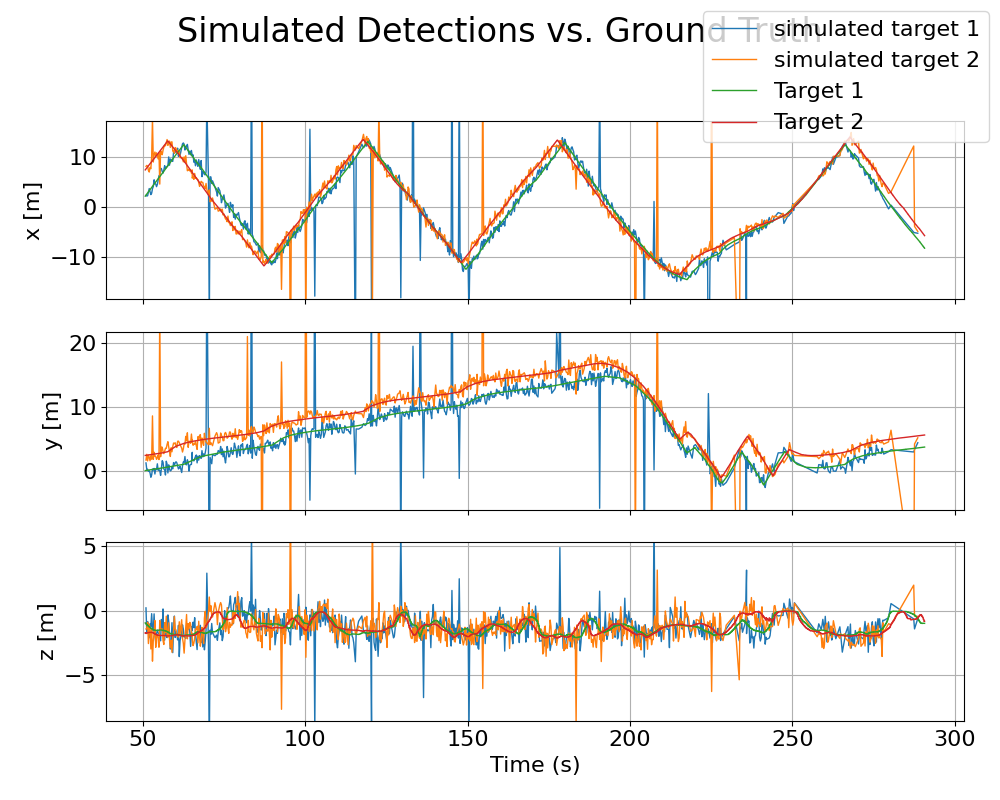

In [7]:
# compare simualted detections with ground truth
fig_sim_gt = pu.plot_xyz_over_time(measurements_target0_df, label="simulated target 1", noisy_limits=True)
pu.plot_xyz_over_time(measurements_target1_df, fig=fig_sim_gt, label="simulated target 2", noisy_limits=True)
pu.plot_xyz_over_time(topic_data["/machine_1/target_tracker/MTT/GT/target0"], fig=fig_sim_gt, label="Target 1")
pu.plot_xyz_over_time(topic_data["/machine_1/target_tracker/MTT/GT/target1"], fig=fig_sim_gt, label="Target 2")
handles, labels = fig_sim_gt.axes[0].get_legend_handles_labels()
fig_sim_gt.legend(handles, labels, loc='upper right')
fig_sim_gt.suptitle("Simulated Detections vs. Ground Truth")
fig_sim_gt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [ ]:
# fig_sim_gt.savefig(os.path.join(PLOTS_DIR, "simulated_detections_vs_gt.svg"), dpi=600, bbox_inches='tight')

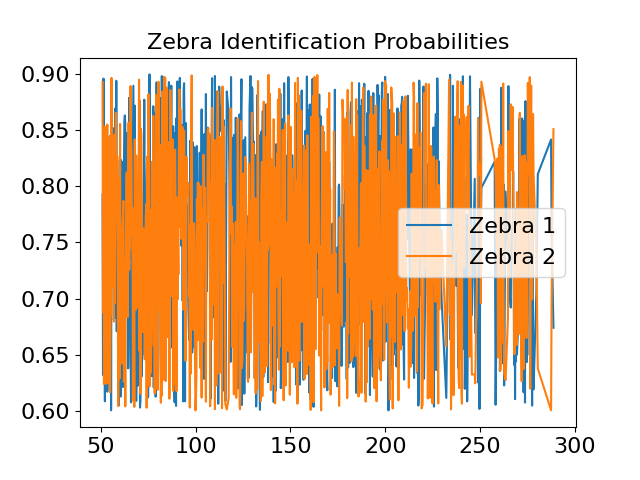

In [9]:
## Plot the simulated probabilities of zebra identification
probabilities_0 = [meas.id for meas in measurements_target0]
probabilities_1 = [meas.id for meas in measurements_target1]
probabilities_0 = np.array(probabilities_0)
probabilities_1 = np.array(probabilities_1)

# sum up the probabilities in each row
zebra_idx_0 = np.sum(probabilities_0, axis=0)
zebra_idx_0 = np.argmax(zebra_idx_0, axis=0)
zebra_idx_1 = np.sum(probabilities_1, axis=0)
zebra_idx_1 = np.argmax(zebra_idx_1, axis=0)

# plot the probabilities over time
fig_prob = plt.figure()
plt.plot(time_target_0, probabilities_0[:, zebra_idx_0], label="Zebra 1")
plt.plot(time_target_1, probabilities_1[:, zebra_idx_1], label="Zebra 2")
plt.title("Zebra Identification Probabilities")
plt.legend()
plt.show()

In [ ]:
# fig_prob.savefig(os.path.join(PLOTS_DIR, "zebra_identification_probabilities.svg"), dpi=600, bbox_inches='tight')

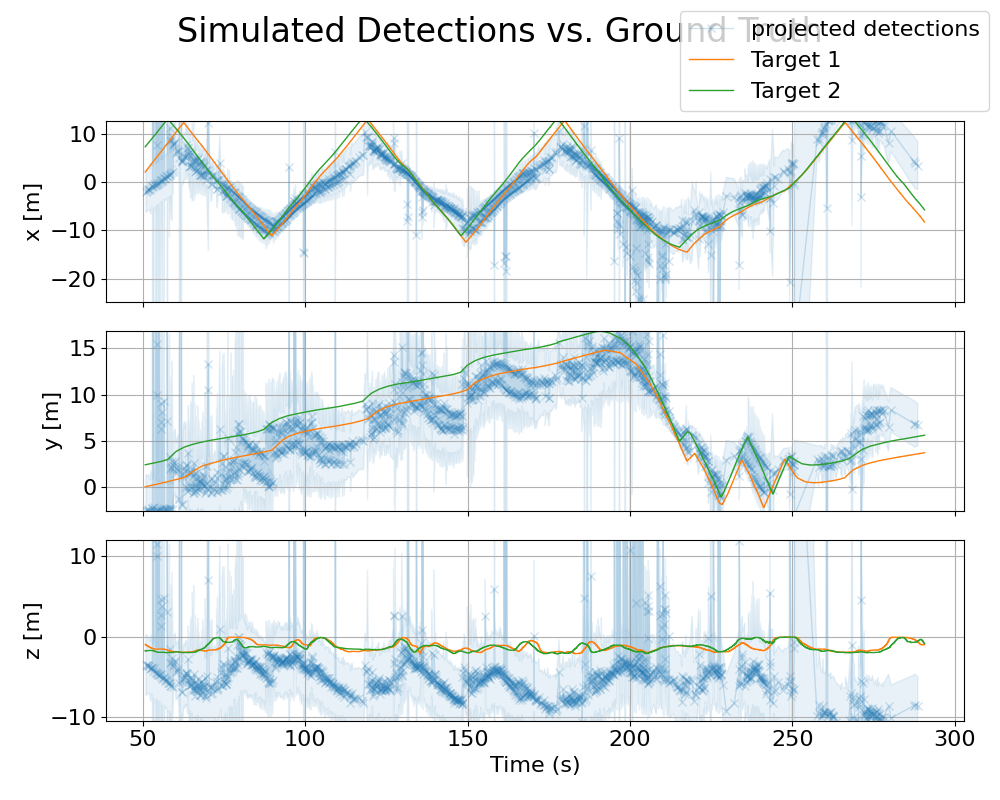

In [11]:
# compare projected detections with ground truth
fig_proj_gt = pu.plot_xyz_over_time(topic_data["/machine_1/object_detections/projected_to_world"], label="projected detections", noisy_limits=True, show_uncertainty=True, alpha=0.2, marker='x')
pu.plot_xyz_over_time(topic_data["/machine_1/target_tracker/MTT/GT/target0"], fig=fig_proj_gt, label="Target 1")
pu.plot_xyz_over_time(topic_data["/machine_1/target_tracker/MTT/GT/target1"], fig=fig_proj_gt, label="Target 2")
handles, labels = fig_proj_gt.axes[0].get_legend_handles_labels()
fig_proj_gt.legend(handles, labels, loc='upper right')
fig_proj_gt.suptitle("Simulated Detections vs. Ground Truth")
fig_proj_gt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [ ]:
# fig_proj_gt.savefig(os.path.join(PLOTS_DIR, "projected_detections_vs_gt.svg"), dpi=600, bbox_inches='tight')

## Initialize Tracking Classes

In [ ]:
gater = mtt.MahalanobisGater()
id_gater = mtt.IDGater()
likelihood = mtt.PDFLikelihood()
id_likelihood = mtt.IdLikelihood()
mh_likelihood = mtt.MahalanobisLikelihood()
filter = mtt.KFTrack()
score_logic = mtt.ScoreLogic()
mn_logic = mtt.MNLogic()

## TEST 1: MHT Tracker using projected measurements

In [ ]:
tracker = mtt.MultiHypothesisTracker(
    filter_obj=filter,
    gater=gater,
    likelihood=likelihood,
    track_logic=mn_logic,
    drone_id=None, # offset estimation for single drone tracking
    max_hypotheses=5,
)

logger.info("Starting tracking using position measurements")
# Evaluate the tracker using the grouped measurements
for measurements in tqdm.tqdm(proj_gdata, total=len(proj_gdata), desc="Proj Position Tracking"):
    tracker.evaluate(measurements)
mht_proj_results = tracker.hypotheses[-1][0].tracks
print(f"Number of tracks: {len(mht_proj_results)}")

INFO: Starting tracking using position measurements
Proj Position Tracking: 100%|██████████| 793/793 [01:34<00:00,  8.38it/s]

Number of tracks: 6


In [15]:

## Extract confirmed tracks
confirmed_proj_tracks = [track for track in mht_proj_results if track.stage == mtt.TrackStage.CONFIRMED or track.stage == mtt.TrackStage.ARCHIVED]
print("############### Projected Pos TRACKS ###############")
# Uncomment the following lines to print detailed information about each confirmed track
# for track in confirmed_proj_tracks:
#     print(f"Track ID: {track.id}, Stage: {track.stage}, Length: {len(track.timestamp_history)}")
#     print(f"Track Score: {track.score}")
print(f"Number of confirmed tracks: {len(confirmed_proj_tracks)}")
mht_proj_results_df = [dfu.track_to_dataframe(track) for track in confirmed_proj_tracks]

############### Projected Pos TRACKS ###############
Number of confirmed tracks: 3


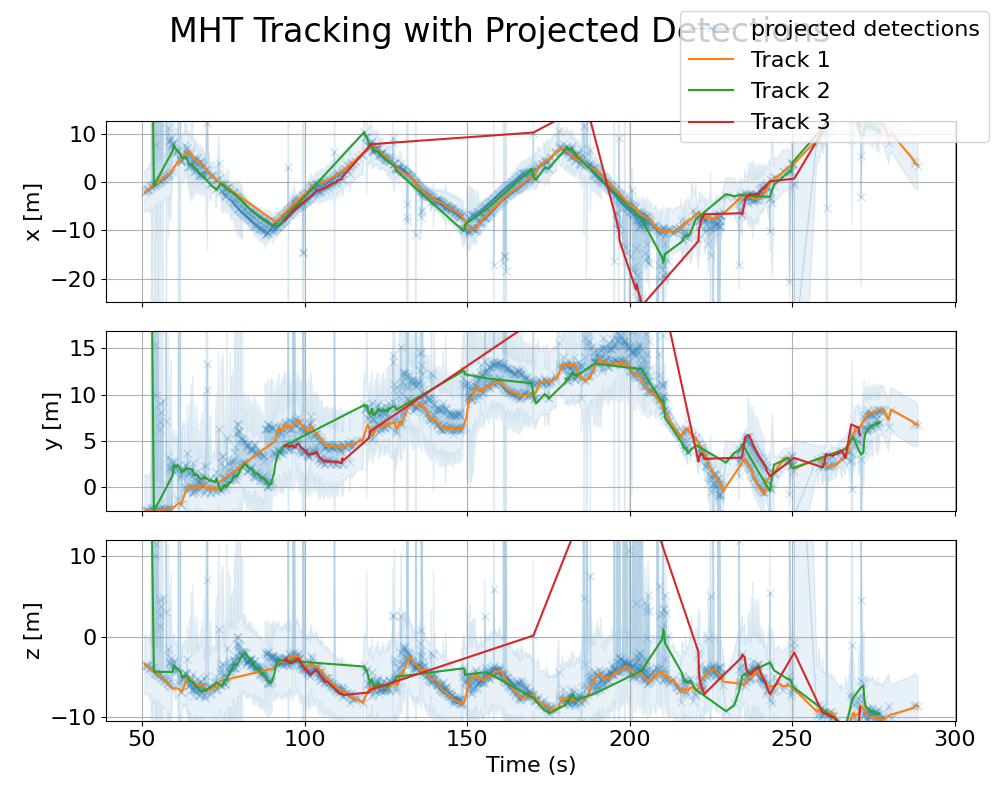

In [16]:
# MHT with projected detections
fig_mht_proj = pu.plot_xyz_over_time(topic_data["/machine_1/object_detections/projected_to_world"], label="projected detections", noisy_limits=True, show_uncertainty=True, alpha=0.2, marker='x')
# pu.plot_xyz_over_time(topic_data["/machine_1/target_tracker/MTT/GT/target0"], fig=fig_mht_proj, label="Target 1")
# pu.plot_xyz_over_time(topic_data["/machine_1/target_tracker/MTT/GT/target1"], fig=fig_mht_proj, label="Target 2")
for i, track_df in enumerate(mht_proj_results_df):
    pu.plot_xyz_over_time(track_df, fig=fig_mht_proj, label=f"Track {i+1}", linewidth=1.5)
handles, labels = fig_mht_proj.axes[0].get_legend_handles_labels()
fig_mht_proj.legend(handles, labels, loc='upper right')
fig_mht_proj.suptitle("MHT Tracking with Projected Detections")
fig_mht_proj.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [ ]:
# fig_mht_proj.savefig(os.path.join(PLOTS_DIR, "mht_projected_detections.svg"), dpi=600, bbox_inches='tight')

In [ ]:
## TEST 2: MHT Tracker using simulated measurements
id_tracker = mtt.MultiHypothesisTracker(
    filter_obj=filter,
    likelihood=id_likelihood,
    gater=gater,
    track_logic=mn_logic,
    drone_id=None, # offset estimation for single drone tracking
    pruning_threshold=0.98,
    max_hypotheses=10,
    max_branches=2,
)

logger.info("Starting tracking using ID measurements")
# Evaluate the tracker using the grouped measurements
for measurements in tqdm.tqdm(id_gdata, total=len(id_gdata), desc="ID Tracking"):
    id_tracker.evaluate(measurements)
mht_id_results = id_tracker.hypotheses[-1][0].tracks
print(f"Number of tracks: {len(mht_id_results)}")
print(f"probability of the last track: {id_tracker.hypotheses[-1][0].probability}")

INFO: Starting tracking using ID measurements
ID Tracking: 100%|██████████| 788/788 [02:15<00:00,  5.79it/s]

Number of tracks: 10
probability of the last track: 0.10004844702455803


In [19]:
## Extract confirmed tracks
confirmed_id_tracks = [track for track in mht_id_results if track.stage == mtt.TrackStage.CONFIRMED or track.stage == mtt.TrackStage.ARCHIVED]
# confirmed_id_tracks = [track for track in sht_id_results if len(track.timestamp_history) > 10]
print("\n############### ID TRACKS ###############")
# for track in confirmed_id_tracks:
#     print(f"Track ID: {track.id}, Stage: {track.stage}, Length: {len(track.timestamp_history)}")
#     print(f"Track Score: {track.score}")
print(f"Number of confirmed tracks: {len(confirmed_id_tracks)}")
mht_id_results_df = [dfu.track_to_dataframe(track) for track in confirmed_id_tracks]


############### ID TRACKS ###############
Number of confirmed tracks: 9


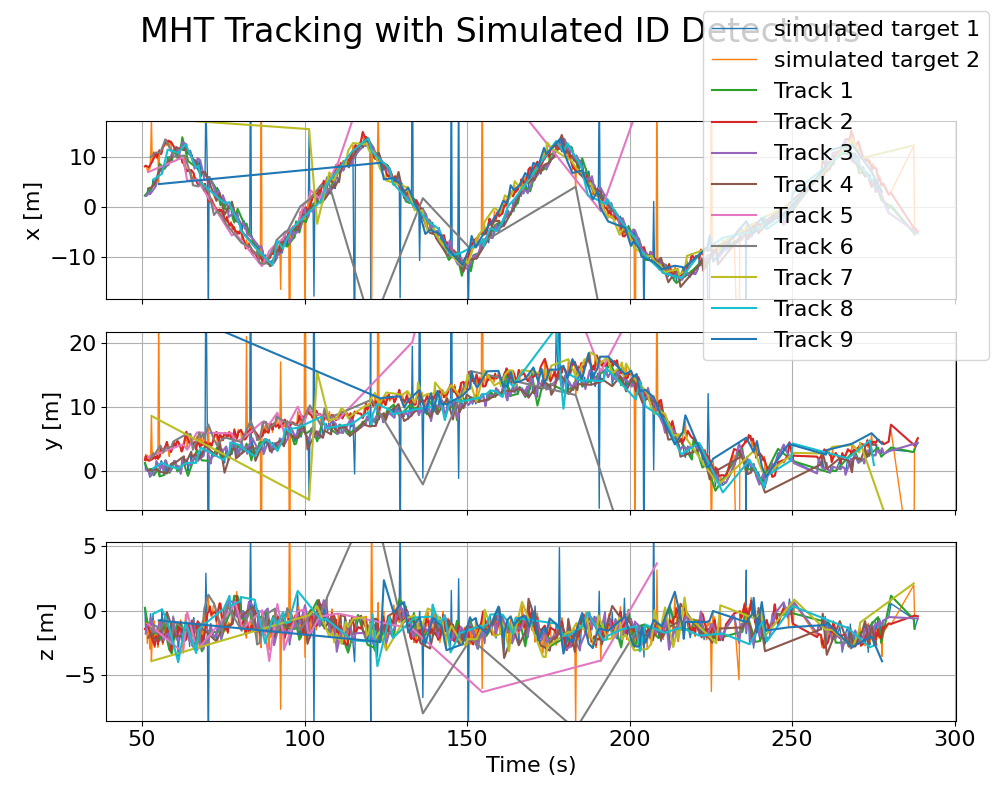

In [20]:
# MHT with simulted id detections
fig_mht_id = pu.plot_xyz_over_time(measurements_target0_df, label="simulated target 1", noisy_limits=True)
pu.plot_xyz_over_time(measurements_target1_df, fig=fig_mht_id, label="simulated target 2", noisy_limits=True)
# pu.plot_xyz_over_time(topic_data["/machine_1/target_tracker/MTT/GT/target0"], fig=fig_mht_id, label="Target 1")
# pu.plot_xyz_over_time(topic_data["/machine_1/target_tracker/MTT/GT/target1"], fig=fig_mht_id, label="Target 2")
for i, track_df in enumerate(mht_id_results_df):
    pu.plot_xyz_over_time(track_df, fig=fig_mht_id, label=f"Track {i+1}", linewidth=1.5)
handles, labels = fig_mht_id.axes[0].get_legend_handles_labels()
fig_mht_id.legend(handles, labels, loc='upper right')
fig_mht_id.suptitle("MHT Tracking with Simulated ID Detections")
fig_mht_id.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [ ]:
# fig_mht_id.savefig(os.path.join(PLOTS_DIR, "mht_id_detections.svg"), dpi=600, bbox_inches='tight')

## TEST 3: JPDA Tracker using simulated position measurements

In [ ]:
pos_tracker = mtt.MultiHypothesisTracker(
    filter_obj=filter,
    gater=gater,
    likelihood=mh_likelihood,
    track_logic=mn_logic,
    drone_id=None, # offset estimation for single drone tracking
    pruning_threshold=0.98,
    max_hypotheses=10,
    max_branches=2,
)

logger.info("Starting tracking using position measurements")
# Evaluate the tracker using the grouped measurements
for measurements in tqdm.tqdm(id_gdata, total=len(id_gdata), desc="Simulated Position Tracking"):
    pos_tracker.evaluate(measurements)
mht_sim_results = pos_tracker.tracks
print(f"Number of tracks: {len(mht_sim_results)}")

INFO: Starting tracking using position measurements
ID Position Tracking: 100%|██████████| 788/788 [02:29<00:00,  5.28it/s]

Number of tracks: 0


In [23]:
## Extract confirmed tracks
confirmed_sim_tracks = [track for track in mht_sim_results if track.stage == mtt.TrackStage.CONFIRMED or track.stage == mtt.TrackStage.ARCHIVED]
print("\n############### Simulated Pos TRACKS ###############")
# Uncomment the following lines to print detailed information about each confirmed track
for track in confirmed_sim_tracks:
    print(f"Track ID: {track.id}, Stage: {track.stage}, Length: {len(track.timestamp_history)}")
    print(f"Track Score: {track.score}")
print(f"Number of confirmed tracks: {len(confirmed_sim_tracks)}")
mht_sim_pos_results_df = [dfu.track_to_dataframe(track) for track in confirmed_sim_tracks]


############### Simulated Pos TRACKS ###############
Number of confirmed tracks: 0


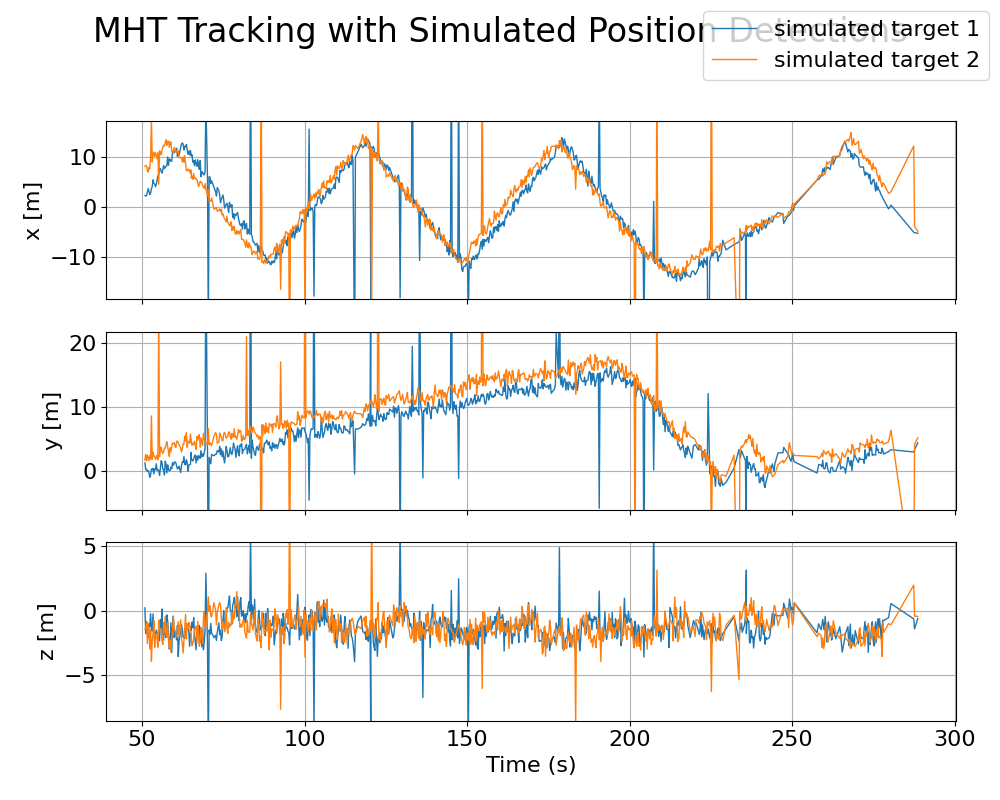

In [24]:
# MHT with simulated position detections
fig_mht_sim_pos = pu.plot_xyz_over_time(measurements_target0_df, label="simulated target 1", noisy_limits=True)
pu.plot_xyz_over_time(measurements_target1_df, fig=fig_mht_sim_pos, label="simulated target 2", noisy_limits=True)
# pu.plot_xyz_over_time(topic_data["/machine_1/target_tracker/MTT/GT/target0"], fig=fig_mht_sim_pos, label="Target 1")
# pu.plot_xyz_over_time(topic_data["/machine_1/target_tracker/MTT/GT/target1"], fig=fig_mht_sim_pos, label="Target 2")
for i, track_df in enumerate(mht_sim_pos_results_df):
    pu.plot_xyz_over_time(track_df, fig=fig_mht_sim_pos, label=f"Track {i+1}", linewidth=1.5)
handles, labels = fig_mht_sim_pos.axes[0].get_legend_handles_labels()
fig_mht_sim_pos.legend(handles, labels, loc='upper right')
fig_mht_sim_pos.suptitle("MHT Tracking with Simulated Position Detections")
fig_mht_sim_pos.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [ ]:
# fig_mht_sim_pos.savefig(os.path.join(PLOTS_DIR, "mht_simulated_position_detections.svg"), dpi=600, bbox_inches='tight')